### **Figure 1a. Population sampling of _anopheles arabiensis_ in The Gambia**

In [1]:
%pip install -q malariagen_data

In [2]:
%pip install -q "plotly<6" kaleido==0.2.1

In [3]:
from google.colab import output
output.enable_custom_widget_manager()

In [4]:
# Import libraries
import os
import re
import plotly.express as px
import pandas as pd
import ipyleaflet
from ipyleaflet import basemaps, Map, CircleMarker, LayersControl, basemaps, basemap_to_tiles, LegendControl, Marker, DivIcon
from ipywidgets import HTML

In [5]:
import malariagen_data

In [6]:
ag3=malariagen_data.Ag3()
ag3

<MalariaGEN Ag3 API client>
Storage URL                           : gs://vo_agam_release_master_us_central1/
Data releases available               : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14, 3.15, 3.16
Results cache                         : None
Cohorts analysis                      : 20260120
AIM analysis                          : 20220528
Site filters analysis                 : dt_20200416
Software version                      : malariagen_data 15.10.0
Client location                       : Oregon, United States (Google Cloud us-west1)
Data filtered to unrestricted use only: False
Data filtered to surveillance use only: False
Relevant data releases                : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14, 3.15, 3.16
---
Please note that data are subject to terms of use,
for more information see the Vector Observatory website https://www.malariagen.net/vobs/
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v15.10.0/Ag3.html

In [7]:
gambia_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160'"

In [8]:
# access metadata
df_samples_gambia = ag3.sample_metadata(sample_query=gambia_sample_query)
df_samples_gambia

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47721-6366STDY9854330,C1161,Kevin Opondo,"Gambia, The",Jareng,2019,9,13.620,-15.190,F,...,Janjanbureh,GM-M,Niamina East,coluzzii,GM-M_colu_2019,GM-M_colu_2019_09,GM-M_colu_2019_Q3,GM-M_Niamina-East_colu_2019,GM-M_Niamina-East_colu_2019_09,GM-M_Niamina-East_colu_2019_Q3
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
2,VBS47724-6366STDY9854333,C2526,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377,VBS48172-6366STDY9854773,W2393,Kevin Opondo,"Gambia, The",Bullock,2019,9,13.181,-16.414,F,...,Brikama,GM-W,Foni Brefet,bissau,GM-W_biss_2019,GM-W_biss_2019_09,GM-W_biss_2019_Q3,GM-W_Foni-Brefet_biss_2019,GM-W_Foni-Brefet_biss_2019_09,GM-W_Foni-Brefet_biss_2019_Q3
378,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
379,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
380,VBS48175-6366STDY9854776,W1807,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3


In [9]:
ag3.sample_metadata(sample_query="country == 'Gambia, The' and taxon == 'arabiensis'").groupby("cohort_admin2_year").size()

,0
cohort_admin2_year,
GM-L_Jarra-East_arab_2001,1
GM-L_Jarra-East_arab_2019,6
GM-L_Jarra-West_arab_2005,2
GM-L_Kiang-West_arab_2005,42
GM-M_Janjanbureh_arab_2021,2
GM-M_Lower-Fuladu-West_arab_2019,53
GM-M_Niamina-East_arab_2019,17
GM-M_Niamina-West_arab_2019,8
GM-M_Niani_arab_2019,243


In [10]:
# total number of mosquitoes collected by species level
df_gambia = ag3.count_samples(sample_query=gambia_sample_query)
df_gambia

taxon                                                      arabiensis  bissau  \
country     admin1_iso admin1_name admin2_name       year                       
Gambia, The GM-L       Mansakonko  Jarra East        2001           1       0   
                                                     2019           6       0   
            GM-M       Janjanbureh Lower Fuladu West 2019          51       0   
                                   Niamina Dankunku  2019           0       1   
                                   Niamina East      2019          10       0   
                                   Niamina West      2019           8       0   
                                   Upper Fuladu West 2019          12       0   
                       Kuntaur     Niani             2019           4       0   
            GM-N       Kerewan     Illiasa           2019           3       0   
                                   Lower Niumi       2019          13       0   
            GM-U       Basse       Basse             2019          28       0   
                                   Jimara            2019          37       1   
                                   Sandu             2019           8       0   
                                   Tumana            2019          21       0   
                                   Wuli East         2019           1       0   
            GM-W       Brikama     Foni Brefet       2019           1       4   
                                   Kombo Central     2019          28       0   
                       Kanifing    Bakau             2019           6       0   
                                   Jeshwang          2019          77       0   

taxon                                                      coluzzii  gambiae  \
country     admin1_iso admin1_name admin2_name       year                      
Gambia, The GM-L       Mansakonko  Jarra East        2001         0        0   
                                                     2019         3        0   
            GM-M       Janjanbureh Lower Fuladu West 2019        12        1   
                                   Niamina Dankunku  2019         0        0   
                                   Niamina East      2019         6        0   
                                   Niamina West      2019         1        2   
                                   Upper Fuladu West 2019         4        0   
                       Kuntaur     Niani             2019         4        0   
            GM-N       Kerewan     Illiasa           2019         0        0   
                                   Lower Niumi       2019         0        0   
            GM-U       Basse       Basse             2019         3        4   
                                   Jimara            2019         3       10   
                                   Sandu             2019         1        2   
                                   Tumana            2019         0        0   
                                   Wuli East         2019         0        0   
            GM-W       Brikama     Foni Brefet       2019         0        0   
                                   Kombo Central     2019         0        0   
                       Kanifing    Bakau             2019         0        0   
                                   Jeshwang          2019         0        0   

taxon                                                      unassigned  
country     admin1_iso admin1_name admin2_name       year              
Gambia, The GM-L       Mansakonko  Jarra East        2001           0  
                                                     2019           0  
            GM-M       Janjanbureh Lower Fuladu West 2019           0  
                                   Niamina Dankunku  2019           0  
                                   Niamina East      2019           1  
                                   Niamina West      2019           0  
                                   Upper 

In [11]:
# remove sample from 2001
query_gm = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160' and year != 2001"

In [12]:
df_gambia2 = ag3.count_samples(sample_query=query_gm)
df_gambia2

taxon                                                      arabiensis  bissau  \
country     admin1_iso admin1_name admin2_name       year                       
Gambia, The GM-L       Mansakonko  Jarra East        2019           6       0   
            GM-M       Janjanbureh Lower Fuladu West 2019          51       0   
                                   Niamina Dankunku  2019           0       1   
                                   Niamina East      2019          10       0   
                                   Niamina West      2019           8       0   
                                   Upper Fuladu West 2019          12       0   
                       Kuntaur     Niani             2019           4       0   
            GM-N       Kerewan     Illiasa           2019           3       0   
                                   Lower Niumi       2019          13       0   
            GM-U       Basse       Basse             2019          28       0   
                                   Jimara            2019          37       1   
                                   Sandu             2019           8       0   
                                   Tumana            2019          21       0   
                                   Wuli East         2019           1       0   
            GM-W       Brikama     Foni Brefet       2019           1       4   
                                   Kombo Central     2019          28       0   
                       Kanifing    Bakau             2019           6       0   
                                   Jeshwang          2019          77       0   

taxon                                                      coluzzii  gambiae  \
country     admin1_iso admin1_name admin2_name       year                      
Gambia, The GM-L       Mansakonko  Jarra East        2019         3        0   
            GM-M       Janjanbureh Lower Fuladu West 2019        12        1   
                                   Niamina Dankunku  2019         0        0   
                                   Niamina East      2019         6        0   
                                   Niamina West      2019         1        2   
                                   Upper Fuladu West 2019         4        0   
                       Kuntaur     Niani             2019         4        0   
            GM-N       Kerewan     Illiasa           2019         0        0   
                                   Lower Niumi       2019         0        0   
            GM-U       Basse       Basse             2019         3        4   
                                   Jimara            2019         3       10   
                                   Sandu             2019         1        2   
                                   Tumana            2019         0        0   
                                   Wuli East         2019         0        0   
            GM-W       Brikama     Foni Brefet       2019         0        0   
                                   Kombo Central     2019         0        0   
                       Kanifing    Bakau             2019         0        0   
                                   Jeshwang          2019         0        0   

taxon                                                      unassigned  
country     admin1_iso admin1_name admin2_name       year              
Gambia, The GM-L       Mansakonko  Jarra East        2019           0  
            GM-M       Janjanbureh Lower Fuladu West 2019           0  
                                   Niamina Dankunku  2019           0  
                                   Niamina East      2019           1  
                                   Niamina West      2019           0  
                                   Upper Fuladu West 2019           1  
                       Kuntaur     Niani             2019           0  
            GM-N       Kerewan     Illiasa           2019           0  
                                   Lower Niumi       2019 

In [13]:
# access metadata
df_samples_gambia2 = ag3.sample_metadata(sample_query=query_gm)
df_samples_gambia2

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47721-6366STDY9854330,C1161,Kevin Opondo,"Gambia, The",Jareng,2019,9,13.620,-15.190,F,...,Janjanbureh,GM-M,Niamina East,coluzzii,GM-M_colu_2019,GM-M_colu_2019_09,GM-M_colu_2019_Q3,GM-M_Niamina-East_colu_2019,GM-M_Niamina-East_colu_2019_09,GM-M_Niamina-East_colu_2019_Q3
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
2,VBS47724-6366STDY9854333,C2526,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,VBS48172-6366STDY9854773,W2393,Kevin Opondo,"Gambia, The",Bullock,2019,9,13.181,-16.414,F,...,Brikama,GM-W,Foni Brefet,bissau,GM-W_biss_2019,GM-W_biss_2019_09,GM-W_biss_2019_Q3,GM-W_Foni-Brefet_biss_2019,GM-W_Foni-Brefet_biss_2019_09,GM-W_Foni-Brefet_biss_2019_Q3
377,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
378,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
379,VBS48175-6366STDY9854776,W1807,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3


In [14]:
gambia_region_taxon = (
    df_samples_gambia2
    .pivot_table(
        index="admin1_name",
        columns="taxon",
        values="sample_id",
        aggfunc="count",
        fill_value=0
    )
)
gambia_region_taxon

taxon,arabiensis,bissau,coluzzii,gambiae,unassigned
admin1_name,,,,,
Basse,95,1,7,16,3
Brikama,29,4,0,0,0
Janjanbureh,81,1,23,3,2
Kanifing,83,0,0,0,0
Kerewan,16,0,0,0,0
Kuntaur,4,0,4,0,0
Mansakonko,6,0,3,0,0


In [15]:
total_arabiensis = gambia_region_taxon["arabiensis"].sum()
total_arabiensis

np.int64(314)

In [16]:
from google.colab import drive
drive.mount("drive")

Drive already mounted at drive; to attempt to forcibly remount, call drive.mount("drive", force_remount=True).


In [17]:
results_dir = 'drive/MyDrive/Colab Data/gm-analysis/'
os.makedirs(results_dir, exist_ok=True)

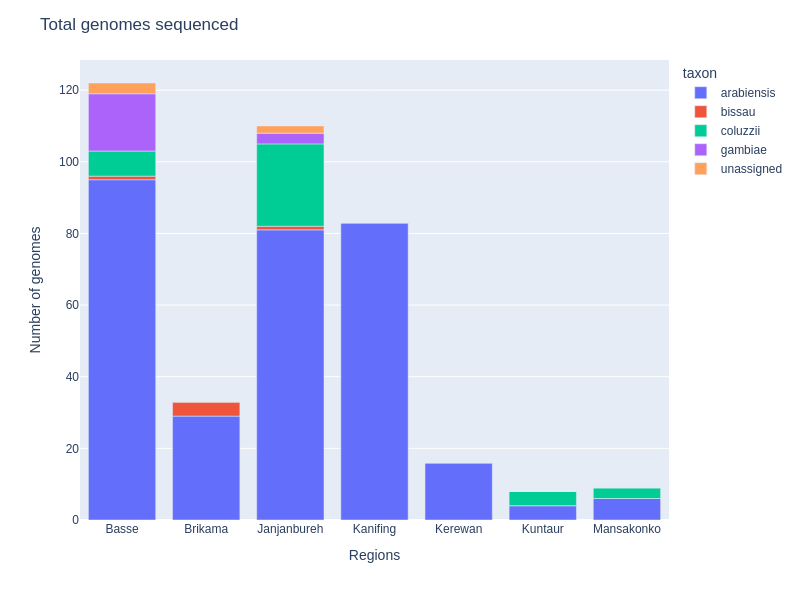

In [18]:
admin1_fig = px.bar(gambia_region_taxon, height=600, width=800)
admin1_fig.update_layout(
    title="Total genomes sequenced",
    yaxis_title="Number of genomes",
    xaxis_title="Regions",
)
admin1_fig.show(renderer="png")

admin1_fig.write_image(os.path.join(results_dir, "fig1a_admin1.png"), scale=2)

In [19]:
gambia_location_taxon = (
    df_samples_gambia2
    .pivot_table(
        index=["location", "latitude", "longitude"],
        columns=["taxon"],
        values="sample_id",
        aggfunc="count",
        fill_value=0,
    )
)

gambia_location_taxon

,,taxon,arabiensis,bissau,coluzzii,gambiae,unassigned
location,latitude,longitude,,,,,
Baja Kunda,13.470,-14.050,1,0,0,0,0
Bakau,13.476,-16.674,6,0,0,0,0
Bansang,13.434,-14.655,12,0,4,0,1
Boiram,13.503,-14.926,12,0,0,1,0
Brikama-A,13.290,-16.657,28,0,0,0,0
Bullock,13.181,-16.414,1,4,0,0,0
Damba kunda Kuta,13.260,-14.268,6,1,0,4,1
Dongoroba,13.380,-15.294,6,0,3,0,0
Ebotown,13.438,-16.674,19,0,0,0,0


In [23]:
# arabiensis

m = ag3.plot_samples_interactive_map(
    sample_query="taxon == 'arabiensis' and country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160'",
    center=(13.5, -15),
    zoom=9,
    basemap=basemaps.OpenStreetMap.Mapnik,
    min_samples=2,
)

m.save(os.path.join(results_dir, "arabiensis_admin2_map.html"), title="An. arabiensis sampling, The Gambia")
m


Map(center=[13.5, -15], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_…

Samples color mappings

In [24]:
# Define color mapping for each admin1 unit
color_mapping_admin1 = {
    'Basse':'teal',
    'Janjanbureh':'navy',
    'Kuntaur':'firebrick',
    'Mansakonko':'plum',
    'Kerewan':'olive',
    'Brikama':'deeppink',
    'Kanifing':'purple'
}

In [25]:
# Define color mapping for each admin2 unit
color_mapping_admin2 = {
    'Jarra East': '#8e8c84',
    'Lower Fuladu West': '#7f7f7f',
    'Upper Fuladu West': '#6b705c',
    'Niani': '#4a4e4d',
    'Niamina East': '#3b5c40',
    'Jimara': '#8e7d32',
    'Basse': '#a95b29',
    'Wuli East': '#b64d3b',
    'Tumana': '#8a4b39',
    'Niamina West': '#6f4e37',
    'Sandu': '#3e3a3a',
    'Jeshwang': '#a4c9e2',
    'Kombo Central': '#78aaff',
    'Lower Niumi': '#4d88ff',
    'Bakau': '#0077b6',
    'Illiasa': '#0096c7',
    'Foni Brefet': '#00b4d8'
}

In [31]:
# access metadata
gm_arab_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160' and taxon == 'arabiensis' and year != 2001"

In [32]:
# access metadata
met_gambia_arab = ag3.sample_metadata(sample_query=gm_arab_sample_query)
met_gambia_arab

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
1,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
2,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
3,VBS47729-6366STDY9854338,C2710,Kevin Opondo,"Gambia, The",Boiram,2019,10,13.503,-14.926,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_10,GM-M_arab_2019_Q4,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_10,GM-M_Lower-Fuladu-West_arab_2019_Q4
4,VBS47731-6366STDY9854340,C2524,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309,VBS48167-6366STDY9854768,W1491,Kevin Opondo,"Gambia, The",Essau,2019,10,13.481,-16.515,F,...,Kerewan,GM-N,Lower Niumi,arabiensis,GM-N_arab_2019,GM-N_arab_2019_10,GM-N_arab_2019_Q4,GM-N_Lower-Niumi_arab_2019,GM-N_Lower-Niumi_arab_2019_10,GM-N_Lower-Niumi_arab_2019_Q4
310,VBS48171-6366STDY9854772,W2321,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3
311,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
312,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3


In [33]:
# Apply color mapping to the metadata
met_gambia_arab['color1'] = met_gambia_arab['admin1_name'].map(color_mapping_admin1)

In [34]:
# Apply color mapping to the metadata
met_gambia_arab['color2'] = met_gambia_arab['admin2_name'].map(color_mapping_admin2)

In [35]:
met_gambia_arab

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter,color1,color2
0,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3,plum,#8e8c84
1,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3,navy,#7f7f7f
2,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3,navy,#6b705c
3,VBS47729-6366STDY9854338,C2710,Kevin Opondo,"Gambia, The",Boiram,2019,10,13.503,-14.926,F,...,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_10,GM-M_arab_2019_Q4,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_10,GM-M_Lower-Fuladu-West_arab_2019_Q4,navy,#7f7f7f
4,VBS47731-6366STDY9854340,C2524,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3,navy,#6b705c
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309,VBS48167-6366STDY9854768,W1491,Kevin Opondo,"Gambia, The",Essau,2019,10,13.481,-16.515,F,...,Lower Niumi,arabiensis,GM-N_arab_2019,GM-N_arab_2019_10,GM-N_arab_2019_Q4,GM-N_Lower-Niumi_arab_2019,GM-N_Lower-Niumi_arab_2019_10,GM-N_Lower-Niumi_arab_2019_Q4,olive,#4d88ff
310,VBS48171-6366STDY9854772,W2321,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3,deeppink,#78aaff
311,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3,purple,#a4c9e2
312,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3,purple,#a4c9e2


In [36]:

# Create base map centered on The Gambia
streetmap = basemap_to_tiles(basemaps.OpenStreetMap)
m = Map(center=(13.4432, -15.3101), zoom=8)
m.add_layer(streetmap)

# Add translucent text labels
admin2_centroids = met_gambia_arab.groupby('admin2_name')[['latitude', 'longitude']].mean().reset_index()

# Define offsets for text box placement
lat_offset = 0.03   # positive = north, negative = south
lon_offset = 0.03  # positive = east, negative = west


for _, row in admin2_centroids.iterrows():
    color = color_mapping_admin2.get(row['admin2_name'], 'gray')

    label_html = f"""
    <div style="
        background: rgba(255, 255, 255, 0.5);
        border: 1.5px solid rgba(0, 0, 0, 0.4);
        border-radius: 15px;
        padding: 8px 12px;
        font-size: 12px;
        font-weight: bold;
        color: {color};
        text-align: center;
        white-space: nowrap;
        box-shadow: 0 0 8px rgba(0,0,0,0.25);
        #backdrop-filter: blur(2px);
        line-height: 1.3;
        width: max-content;
        pointer-events: none;
    ">
        {row['admin2_name']}
    </div>
    """

    # Shift label slightly south (below point) to reduce overlap
    label_marker = Marker(
        location=(row['latitude'] + lat_offset, row['longitude'] - lon_offset),
        icon=DivIcon(html=label_html, icon_size=(0, 0))
    )
    m.add_layer(label_marker)

# Add circle markers (on top of labels)
for _, row in met_gambia_arab.iterrows():
    color = color_mapping_admin2.get(row['admin2_name'], 'gray')

    marker = CircleMarker(
        location=(row['latitude'], row['longitude']),
        radius=5,
        color=color,
        fill_color=color,
        fill_opacity=1.5,
        weight=2
    )

    popup_html = HTML(f"""
        <b>Sample ID:</b> {row['sample_id']}<br>
        <b>Admin1 Name:</b> {row['admin1_name']}<br>
        <b>Admin2 Name:</b> {row['admin2_name']}<br>
        <b>Year:</b> {row['year']}<br>
        <b>Taxon:</b> {row['taxon']}
    """)
    marker.popup = popup_html
    m.add_layer(marker)

# Add legend and layer controls
#m.add_control(LayersControl(position='topright'))
#legend_items = {name: color for name, color in color_mapping_admin2.items()}
#legend = LegendControl(legend_items, name="Administrative Districts", position="bottomright")
#m.add_control(legend)

m.save(os.path.join(results_dir, "fig1a_arabiensis_sampling_map.html"))
m

Map(center=[13.4432, -15.3101], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'z…